# Natural Language Processing



This project will give you practical experience using Natural Language Processing techniques. This project is in three parts:
- in part 1) you will use a dataset in a CSV file
- in part 2) you will use the Wikipedia API to directly access content
on Wikipedia.
- in part 3) you will make your notebook interactive


### Part 1)



- The CSV file is available at https://ddc-datascience.s3.amazonaws.com/Projects/Project.5-NLP/Data/NLP.csv
- The file contains a list of famous people and a brief overview.
- The goal of part 1) is to ...
  1. Pick one person from the list ( the reference person ) and output 10 other people who's overview are "closest" to the reference person in a Natural Language Processing sense
  1. Also output the sentiment of the overview of the reference person



### Part 2)



- For the same reference person that you chose in Part 1), use the Wikipedia API to access the whole content of the reference person's Wikipedia page.
- The goal of Part 2) is to ...
  1. Print out the text of the Wikipedia article for the reference person
  1. Determine the sentiment of the text of the Wikipedia page for the reference person
  1. Collect the text of the Wikipedia pages from the 10 nearest neighbors from Part 1)
  1. Determine the nearness ranking of these 10 people to your reference person based on their entire Wikipedia page
  1. Compare, i.e. plot,  the nearest ranking from Step 1) with the Wikipedia page nearness ranking.  A difference of the rank is one means of comparison.



### Part 3)


Make an interactive notebook where a user can choose or enter a name and the notebook displays the 10 closest individuals.

In addition to presenting the project slides, at the end of the presentation each student will demonstrate their code using a famous person suggested by the other students that exists in the DBpedia set.


## Data Collection

### Import

In [ ]:
import duckdb
import pandas as pd
import os
import numpy as np
from google.colab import userdata


# TextBlob: cleans text (singularize) and scores sentiment
from textblob import TextBlob, Word

# TfidfVectorizer: turns each overview into a row of numbers (one column per word)
from sklearn.feature_extraction.text import TfidfVectorizer

# NearestNeighbors: finds the rows (people) closest to a reference row
from sklearn.neighbors import NearestNeighbors



## Settings

In [ ]:
# ===== Change these for each pass =====
n_rows = 1000        # Pass 05: 1000 | Pass 06: 8000 | Pass 07: 50000 (more than the 42,786 rows, so you get them all)
ref_name = "Jonathan Hoefler"
use_saved = True    # False = do the slow cleaning and save it to Hugging Face
                     # True  = load the cleaning you already saved (fast)

## Convert CSV to Parquet

In [ ]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.5-NLP/Data/NLP.csv'
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.5-NLP/Data/NLP.csv'

In [ ]:
# File name without the extension: 'NLP'
base_file = url.split("/")[-1].split(".")[0]
base_file

'NLP'

In [ ]:
# Read the remote CSV and write it straight to a local parquet file (lesson 102's ETL step)
# No all_varchar here: DuckDB auto-detects types, so number columns stay numbers
con = duckdb.connect()
con.execute(f"""
    COPY (
        SELECT *
        FROM read_csv('{url}')
    )
    TO '{base_file}.parquet'
    (FORMAT PARQUET);
""")

! ls -l {base_file}.parquet

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

-rw-r--r-- 1 root root 49460246 Nov 27 18:09 NLP.parquet


### Push to Hugging Face

In [ ]:
hf_account = os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account

'hmsealy'

In [ ]:
hf_repo = os.environ["HF_REPO"] = "Data_Science-22"
hf_repo

'Data_Science-22'

In [ ]:
hf_file = os.environ["HF_FILE"] = f"{base_file}.parquet"
hf_file

'NLP.parquet'

In [ ]:
# Get the token from Colab Secrets. Only shows the first 3 and last 4 characters
_ = hf_token = os.environ["HF_TOKEN"] = userdata.get('hf_token')
f"{_[:3]} ... {_[-4:]}"

'hf_ ... kJTa'

In [ ]:
! hf auth login --token ${HF_TOKEN}

The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `Colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [ ]:
%%capture hf_upload
%%bash

TARGET_REPO="${HF_ACCOUNT}/${HF_REPO}"
LOCAL_SOURCE="./${HF_FILE}"
REMOTE_DESTINATION="./${HF_FILE}"

hf upload \
  --type dataset \
  "${TARGET_REPO}" \
  "${LOCAL_SOURCE}" \
  "${REMOTE_DESTINATION}"

In [ ]:
print(hf_upload.stdout)

✓ Uploaded
  url: https://huggingface.co/datasets/hmsealy/Data_Science-22/commit/f6f6a260507345d5f590774bd186a534de1ed739



### Download TextBlob word lists

In [ ]:
%%capture
# %%capture hides the long download log
!python -m textblob.download_corpora

## Load Data

### Load first n_rows rows

In [ ]:
# Load the first n_rows rows (set in the Settings cell)
df = duckdb.query(f'select * from "{base_file}.parquet" limit {n_rows}').df()
df.shape

(1000, 3)

## Data checks

In [ ]:
import requests                      # fetch web pages (HTML lecture, 315)
from urllib.parse import unquote     # turns %C3%A9 back into é

### Check 1: Missing names

In [ ]:
# How many rows have no name at all? We want 0.
df["name"].isna().sum()

np.int64(0)

### Check 2: Duplicate names

In [ ]:
# keep=False shows EVERY copy of a repeated name, not just the second one
df[df["name"].duplicated(keep=False)][["name"]]

,name


### Check 3: Names with parentheses

In [ ]:
# Wikipedia adds (job) to tell apart people with the same name, e.g. "Paddy Dunne (Gaelic footballer)"
# regex=False means "(" is just a normal character here
df[df["name"].str.contains("(", regex=False)][["name"]]

,name
17,Paddy Dunne (Gaelic footballer)
27,Ian Mitchell (author)
31,Ted Hill (mathematician)
41,Bob Adams (American football)
50,Professor Lyrical (rapper)
...,...
972,Larry Sawyer (poet)
983,John Hart (speedway rider)
988,Mike Burton (rugby union)
989,Michael Rowe (director)


### Check 4: Names with commas

In [ ]:
# Titles like "Anthony Gueterbock, 18th Baron Berkeley"
df[df["name"].str.contains(",", regex=False)][["name"]]

,name
13,"Anthony Gueterbock, 18th Baron Berkeley"
178,"John Taylor (cricketer, born 1937)"
200,"Mick O'Brien (footballer, born 1979)"
215,"Jose Luis Nazario, Jr."
334,"Chris Curran (footballer, born September 1971)"
526,"John James (footballer, born 1934)"
686,"Jesse Jackson, Jr."
732,"Kevin Rose (footballer, born 1960)"
825,"John O'Neill (footballer, born 1974)"
869,"Andrew Mawson, Baron Mawson"


### Check 5: Names with unusual characters

In [ ]:
# Anything that is NOT a plain letter, space, period, apostrophe or hyphen.
# This catches digits, accents (é, ö), parentheses and commas.
df[df["name"].str.contains(r"[^A-Za-z .'\-]")][["name"]]

,name
13,"Anthony Gueterbock, 18th Baron Berkeley"
17,Paddy Dunne (Gaelic footballer)
27,Ian Mitchell (author)
31,Ted Hill (mathematician)
35,Freimut B%C3%B6rngen
...,...
983,John Hart (speedway rider)
985,"Peta Buscombe, Baroness Buscombe"
988,Mike Burton (rugby union)
989,Michael Rowe (director)


### Check 6: Name not found in its own overview

In [ ]:
# Is the first word of the name in the overview text?
# If not, the person may be known by a stage name (e.g. G-Enka = Henry Kõrvits)
# or an accent was removed in the text (é -> e)
first_words = [n.lower().split()[0] for n in df["name"]]
df["name_in_text"] = [w in t for w, t in zip(first_words, df["text"])]

# ~ means "NOT", so this shows rows where the name was NOT found
df[~df["name_in_text"]][["name", "text"]]

,name,text
4,G-Enka,henry krvits born 30 december 1974 in tallinn ...
33,Bob Reece,robert scott reece born january 5 1951 is an a...
36,Th%C3%BCring Br%C3%A4m,thring brm born 10 april 1944 is a swiss compo...
72,Ulf-Dietrich Reips,prof dr ulfdietrich reips is a full professor ...
75,Vladimir Yurchenko,uladzimir vasilyevich yurchanka belarusian rus...
...,...,...
925,Tom Drury,thomas jay drury is an american writerhe was b...
943,H. Wayne Light,h wayne light phd born 1945 is an academic and...
960,Joseph Gitile Naituli,gitile naituli is a professor of management an...
966,Tony Ghelfi,anthony paul ghelfi born august 23 1961 is a f...


### Check 7: Page title from each URI

In [ ]:
# <http://dbpedia.org/resource/Jonathan_Hoefler>  ->  Jonathan_Hoefler
df["title"] = (
    df["URI"]
    .str.replace("<http://dbpedia.org/resource/", "")
    .str.replace(">", "")
    .apply(unquote)
)

# Does the title match the name? (title uses _ instead of spaces)
df[df["title"].str.replace("_", " ") != df["name"]][["name", "title"]]

,name,title
35,Freimut B%C3%B6rngen,Freimut_Börngen
36,Th%C3%BCring Br%C3%A4m,Thüring_Bräm
73,Marcel J. Melan%C3%A7on,Marcel_J._Melançon
85,Zvonimir Juri%C4%87,Zvonimir_Jurić
122,Se%C3%A1n %C3%93g %C3%93 hAilp%C3%ADn,Seán_Óg_Ó_hAilpín
129,L%C3%A1zaro C%C3%A1rdenas Batel,Lázaro_Cárdenas_Batel
148,Ren%C3%A9 Froger,René_Froger
166,Ant%C3%B3nio Castanheira Neves,António_Castanheira_Neves
182,Mike P%C3%A9rez (baseball),Mike_Pérez_(baseball)
203,David Pastr%C5%88%C3%A1k,David_Pastrňák


### Fix coded names

In [ ]:
# Some names are stored as web-address codes ("B%C3%B6rngen") or got cut off ("author)").
# The title column (built in Check 7) has the correct name, just with _ instead of spaces.
df["name"] = df["title"].str.replace("_", " ")

# Show a few that were fixed
df.loc[[35, 36, 787], "name"]

,name
35,Freimut Börngen
36,Thüring Bräm
787,James Grieve (translator/author)


### Findings (first 1,000 rows)

**Names**
- Missing names: 0
- Duplicate names: 0
- Names with a job in parentheses: 121, e.g. "Paddy Dunne (Gaelic footballer)"
- Names with a comma: 12. Mostly titles ("Andrew Mawson, Baron Mawson"), "Jr." names,
  or a birth year inside parentheses ("John Taylor (cricketer, born 1937)")
- Names with unusual characters: 178 (includes the parentheses and commas above, plus accents)
- Name doesn't match its page title: 54
  - 53 stored as web-address codes, e.g. "Freimut B%C3%B6rngen"
  - 1 cut off: "author)" should be "James Grieve (translator/author)"
  - All 54 fixed by rebuilding the name from the page title
- Name not found in its own overview: 64. Nicknames (Tom = Thomas, Tony = Anthony), stage names (G-Enka),
  accents or hyphens removed from the text

**Wikipedia (Part 2)**
- Only the 30 closest people to Jonathan were checked, not all 1,000 (a full check would take ~10 minutes
  at 1,000 rows and hours at 42,000)
- 1 skipped: Colleen McGill (Part 1 rank 2) has no Wikipedia page, so Neil Cossons (rank 11) was used instead

## Part 1

### Pick the reference person

In [ ]:
ref_index = 12   # Jonathan's row number, found by looking at df (same as with 20 rows)
ref_index

12

### Clean text (singularize)

In [ ]:
# Turn each word into its singular form so "typefaces" and "typeface" count as the same word
def singularize_text(text):
    words = text.split()
    singles = [Word(w).singularize() for w in words]
    return " ".join(singles)

# A different file for each pass size, e.g. NLP_clean_1000.parquet
clean_file = f"NLP_clean_{n_rows}.parquet"
clean_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/{clean_file}"

if use_saved:
    # Fast: load the cleaned text we saved last time (same way as the HF lecture)
    saved = duckdb.query(f'select * from "{clean_url}"').df()
    df["text_clean"] = saved["text_clean"]
else:
    # Slow: clean every overview, then save the result to a parquet file
    df["text_clean"] = df["text"].apply(singularize_text)
    df[["name", "text_clean"]].to_parquet(clean_file)

df[["name", "text_clean"]].head()

,name,text_clean
0,Digby Morrell,digby morrell born 10 october 1979 is a former...
1,Alfred J. Lewy,alfred j lewy aka sandy lewy graduated from un...
2,Harpdog Brown,harpdog brown is a singer and harmonica player...
3,Franz Rottensteiner,franz rottensteiner born in waidmannsfeld lowe...
4,G-Enka,henry krvit born 30 december 1974 in tallinn b...


In [ ]:
# Point the upload cell at the cleaned-text file
os.environ["HF_FILE"] = clean_file
clean_file

'NLP_clean_1000.parquet'

In [ ]:
%%capture hf_upload_clean
%%bash
# Run this cell only when use_saved = False
TARGET_REPO="${HF_ACCOUNT}/${HF_REPO}"
LOCAL_SOURCE="./${HF_FILE}"
REMOTE_DESTINATION="./${HF_FILE}"

hf upload \
  --type dataset \
  "${TARGET_REPO}" \
  "${LOCAL_SOURCE}" \
  "${REMOTE_DESTINATION}"

In [ ]:
# Should say "✓ Uploaded"
print(hf_upload_clean.stdout)

✓ Uploaded
  url: https://huggingface.co/datasets/hmsealy/Data_Science-22/commit/f6f6a260507345d5f590774bd186a534de1ed739



In [ ]:
# stop_words='english' drops filler words like "the", "is", "and"
tfidf_vec = TfidfVectorizer(stop_words="english")

# fit_transform learns the vocabulary and builds the matrix:
# n_rows rows (people) x one column per unique word
tf_idf = tfidf_vec.fit_transform(df["text_clean"])
tf_idf.shape

(1000, 30710)

### Teach NearestNeighbors

In [ ]:
# Teach NearestNeighbors where all n_rows people sit in "word space"
nn = NearestNeighbors().fit(tf_idf)

# Ask for 11 neighbors, not 10: the closest match is always Jonathan himself (distance 0)
distances, indices = nn.kneighbors(
    X = tf_idf[ref_index],
    n_neighbors = 11,
)
distances, indices

(array([[0.        , 1.01502089, 1.31063222, 1.33775524, 1.36145023,
         1.36269295, 1.36838708, 1.36868304, 1.36930606, 1.36940602,
         1.37292162]]),
 array([[ 12, 223, 163, 704, 925, 582, 778, 798, 800, 556, 643]]))

In [ ]:
# Pull out the people at those row numbers, and add their distances
neighbors = df.iloc[indices[0]][["name"]].copy()
neighbors["distance"] = distances[0]

# Drop the first row (Jonathan himself) and keep only the 10 closest
neighbors = neighbors.iloc[1:11]

# Add a rank column: 1 = closest
neighbors.insert(0, "rank", range(1, 11))
neighbors.reset_index(drop=True)

,rank,name,distance
0,1,Tobias Frere-Jones,1.015021
1,2,Colleen McGill,1.310632
2,3,Jeff Madrick,1.337755
3,4,Tom Drury,1.361450
4,5,Robert H. Cumming,1.362693
5,6,Lemi Ghariokwu,1.368387
6,7,Laurence Gartel,1.368683
7,8,Brent Nicholson Earle,1.369306
8,9,Jean Valentine,1.369406
9,10,John Donald (jewellery designer),1.372922


### Sentiment

In [ ]:
# Use the ORIGINAL text for sentiment, not the cleaned text
ref_blob = TextBlob(df.loc[ref_index, "text"])

# polarity: -1 (negative) to +1 (positive)
# subjectivity: 0 (factual) to 1 (opinion)
ref_blob.sentiment

Sentiment(polarity=0.19034090909090906, subjectivity=0.37683080808080804)

## Part 2

### Setup

In [ ]:
%%capture
# The Wikipedia API package (same one used in lessons 504 and 506)
!pip3 install wikipedia-api

In [ ]:
import re                      # regular expressions, for removing special characters
import wikipediaapi            # pulls page text from Wikipedia
import matplotlib.pyplot as plt

#unquote: turns web-address codes back into normal letters, e.g. "Beyonc%C3%A9" -> "Beyoncé"
# DBpedia links may store names this way; Wikipedia needs the real title to find the page
from urllib.parse import unquote


from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # the stop-word list TfidfVectorizer uses

### Candidates: Jonathan + his 30 closest

In [ ]:
# Ask for 30 people, not 10, so there are plenty of spares
# if some have no Wikipedia page
dist_c, idx_c = nn.kneighbors(X=tf_idf[ref_index], n_neighbors=31)
candidate_rows = list(idx_c[0])    # row numbers, closest first (Jonathan is first)
candidate_rows

[np.int64(12),
 np.int64(223),
 np.int64(163),
 np.int64(704),
 np.int64(925),
 np.int64(582),
 np.int64(778),
 np.int64(798),
 np.int64(800),
 np.int64(556),
 np.int64(643),
 np.int64(413),
 np.int64(750),
 np.int64(725),
 np.int64(144),
 np.int64(58),
 np.int64(113),
 np.int64(912),
 np.int64(37),
 np.int64(593),
 np.int64(443),
 np.int64(647),
 np.int64(817),
 np.int64(304),
 np.int64(600),
 np.int64(5),
 np.int64(289),
 np.int64(407),
 np.int64(901),
 np.int64(769),
 np.int64(601)]

### Get Wikipedia pages until we have 10 good ones

In [ ]:
wikip = wikipediaapi.Wikipedia(user_agent="neefmister")

kept_rows = []    # row numbers we keep: Jonathan + 10 people with a real page
kept_texts = []   # their Wikipedia text

# Go down the list, closest first. Skip missing pages and disambiguation pages.
for row in candidate_rows:
    page = wikip.page(df.loc[row, "title"])

    if not page.exists():
        print(f"Skipped {df.loc[row, 'name']}: no Wikipedia page")
    elif "may refer to" in page.text[:500]:
        print(f"Skipped {df.loc[row, 'name']}: disambiguation page")
    else:
        kept_rows.append(row)
        kept_texts.append(page.text)

    # Stop as soon as we have Jonathan + 10 people
    if len(kept_rows) == 11:
        break

len(kept_rows)

Skipped Colleen McGill: no Wikipedia page


11

### Build the Part 2 table

In [ ]:
# One table for Part 2, built straight from the lists above (no splitting)
wiki_df = pd.DataFrame({
    "name": df.loc[kept_rows, "name"].values,
    # position in the candidate list = original Part 1 rank (Jonathan = 0)
    "part1_rank_original": [candidate_rows.index(r) for r in kept_rows],
    # renumber 0-10 so both rankings run 1-10
    "part1_rank": range(0, 11),
    "wiki_text": kept_texts,
})
wiki_df[["name", "part1_rank_original", "part1_rank"]]

,name,part1_rank_original,part1_rank
0,Jonathan Hoefler,0,0
1,Tobias Frere-Jones,1,1
2,Jeff Madrick,3,2
3,Tom Drury,4,3
4,Robert H. Cumming,5,4
5,Lemi Ghariokwu,6,5
6,Laurence Gartel,7,6
7,Brent Nicholson Earle,8,7
8,Jean Valentine,9,8
9,John Donald (jewellery designer),10,9


### Step 1: Reference person's article

In [ ]:
ref_wiki_text = wiki_df.loc[0, "wiki_text"]   # row 0 is Jonathan
print(ref_wiki_text)

Jonathan Hoefler (; born 1970) is an American type designer. Hoefler founded the Hoefler Type Foundry in 1989, a type foundry in New York.

Early life
Jonathan Hoefler was born on August 22, 1970, in New York City to Doreen Benjamin and Charles Hoefler, a theatrical set designer and producer. Growing up, it was the Gill Sans text on boxes of custard that drew him to typography design. He is largely self-taught, and worked with magazine art director Roger Black prior to forming the Hoefler Type Foundry in 1989.

Career
Hoefler's Champion Gothic was inspired by 19th-century wood type. It was commissioned for Sports Illustrated shortly after founding the company in 1989. In 1997, his path crossed with type designer Tobias Frere-Jones when both were trying to purchase German type foundry catalogs. In 1999, Hoefler began working with Frere-Jones, and from 2005 to 2014 the company operated under the name Hoefler & Frere-Jones as a partnership. In 2000, the firm, under Frere-Jones' direction,

### Step 2: Sentiment of the article

In [ ]:
# Use the ORIGINAL article text. Stemming would turn words like "outstanding"
# into "outstand", which TextBlob's sentiment word list doesn't recognize.
# polarity: -1 (negative) to +1 (positive)
# subjectivity: 0 (factual) to 1 (opinion)


TextBlob(ref_wiki_text).sentiment

Sentiment(polarity=0.10662186650558741, subjectivity=0.34973069566092824)

### Clean text: case, special characters, stemming, lemmatization

In [ ]:
def clean_text(text, method):
    # 1. Change case: everything lowercase, so "Apple" and "apple" match
    text = text.lower()

    # 2. Remove possessives: "hoefler's" -> "hoefler"  (handles both ' and ’)
    text = re.sub(r"['’]s\b", "", text)

    # 3. Remove special characters: anything that is NOT a-z, 0-9 or a space becomes a space
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # 4. Split into words and drop stop words ("the", "was", "this" ...)
    #    We drop them BEFORE stemming. Otherwise "was" -> "wa" and "this" -> "thi"
    #    slip past the stop-word list, like the "wa" problem in Pass 01.
    words = [w for w in text.split() if w not in ENGLISH_STOP_WORDS]

    # 5. Stemming or lemmatization
    if method == "stem":
        words = [Word(w).stem() for w in words]        # chops endings: "designed" -> "design", "typefaces" -> "typefac"
    elif method == "lemma":
        words = [Word(w).lemmatize() for w in words]   # dictionary form: "typefaces" -> "typeface"

    return " ".join(words)

# See the difference on the first 300 characters of Jonathan's page
sample = ref_wiki_text[:300]
print("ORIGINAL:", sample, "\n")
print("STEM:    ", clean_text(sample, "stem"), "\n")
print("LEMMA:   ", clean_text(sample, "lemma"))

ORIGINAL: Jonathan Hoefler (; born 1970) is an American type designer. Hoefler founded the Hoefler Type Foundry in 1989, a type foundry in New York.

Early life
Jonathan Hoefler was born on August 22, 1970, in New York City to Doreen Benjamin and Charles Hoefler, a theatrical set designer and producer. Growin 

STEM:     jonathan hoefler born 1970 american type design hoefler found hoefler type foundri 1989 type foundri new york earli life jonathan hoefler born august 22 1970 new york citi doreen benjamin charl hoefler theatric set design produc growin 

LEMMA:    jonathan hoefler born 1970 american type designer hoefler founded hoefler type foundry 1989 type foundry new york early life jonathan hoefler born august 22 1970 new york city doreen benjamin charles hoefler theatrical set designer producer growin


### Step 4: Wikipedia nearness ranking

In [ ]:
def wiki_ranking(method):
    # Clean all 11 pages the chosen way
    cleaned = wiki_df["wiki_text"].apply(lambda t: clean_text(t, method))

    # Same TF-IDF + nearest neighbors as Part 1, but on 11 full pages
    matrix = TfidfVectorizer().fit_transform(cleaned)
    nn_wiki = NearestNeighbors().fit(matrix)
    dist, idx = nn_wiki.kneighbors(matrix[0], n_neighbors=len(wiki_df))   # row 0 = Jonathan

    # idx lists rows from closest to farthest. Turn that into "row -> rank".
    ranks = pd.Series(range(len(idx[0])), index=idx[0])
    return ranks.sort_index().values   # back in wiki_df row order

wiki_df["wiki_rank_stem"]  = wiki_ranking("stem")
wiki_df["wiki_rank_lemma"] = wiki_ranking("lemma")

### Step 5: Compare rankings

In [ ]:
# Leave out Jonathan (row 0) and work out how far each person moved
compare = wiki_df.loc[1:, ["name", "part1_rank_original", "part1_rank", "wiki_rank_stem", "wiki_rank_lemma"]].copy()

# Positive = moved CLOSER on Wikipedia; negative = moved farther away
compare["change_stem"]  = compare["part1_rank"] - compare["wiki_rank_stem"]
compare["change_lemma"] = compare["part1_rank"] - compare["wiki_rank_lemma"]
compare

,name,part1_rank_original,part1_rank,wiki_rank_stem,wiki_rank_lemma,change_stem,change_lemma
1,Tobias Frere-Jones,1,1,1,1,0,0
2,Jeff Madrick,3,2,4,2,-2,0
3,Tom Drury,4,3,8,7,-5,-4
4,Robert H. Cumming,5,4,5,3,-1,1
5,Lemi Ghariokwu,6,5,3,8,2,-3
6,Laurence Gartel,7,6,6,5,0,1
7,Brent Nicholson Earle,8,7,7,9,0,-2
8,Jean Valentine,9,8,10,10,-2,-2
9,John Donald (jewellery designer),10,9,2,4,7,5
10,Neil Cossons,11,10,9,6,1,4


### Step 5, plot

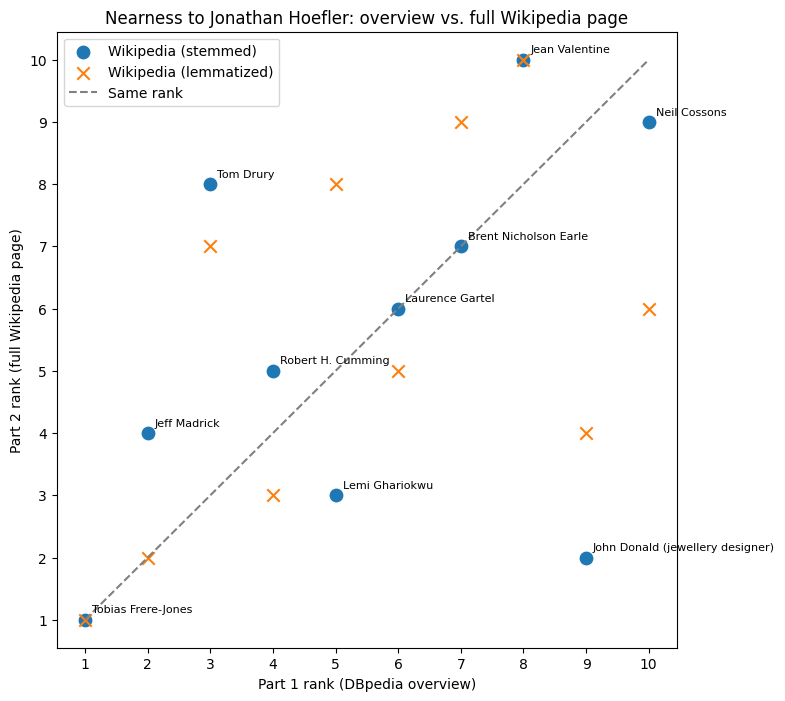

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))

# Each dot is one person: x = Part 1 rank, y = Wikipedia rank
ax.scatter(compare["part1_rank"], compare["wiki_rank_stem"],  label="Wikipedia (stemmed)",    s=80)
ax.scatter(compare["part1_rank"], compare["wiki_rank_lemma"], label="Wikipedia (lemmatized)", s=80, marker="x")

# Label the stemmed dots with names
for _, row in compare.iterrows():
    ax.annotate(row["name"], (row["part1_rank"], row["wiki_rank_stem"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)

# Dashed line = "same rank both ways". Dots far from it changed the most.
ax.plot([1, 10], [1, 10], linestyle="--", color="gray", label="Same rank")

ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.set_xlabel("Part 1 rank (DBpedia overview)")
ax.set_ylabel("Part 2 rank (full Wikipedia page)")
ax.set_title("Nearness to Jonathan Hoefler: overview vs. full Wikipedia page")
ax.legend()
plt.show()

## Part 3

### Setup

In [ ]:
# interact turns a function into a widget (lecture 413)
# widgets gives us the Combobox: a text box that suggests names as you type
from ipywidgets import interact
import ipywidgets as widgets

### List of names to choose from

In [ ]:
# All names A-Z, plus a set for fast "is this a real name?" checks
names = sorted(df["name"])
name_set = set(names)
len(names)

1000

### Pick a person, see the 10 closest

In [ ]:
# A text box that suggests matching names as you type
name_box = widgets.Combobox(
    options=names,
    value="Jonathan Hoefler",
    placeholder="Type a name...",
    description="person",
)

def show_closest(person):
    if person not in name_set:
        # While you're still typing, the text isn't a full name yet
        print("Keep typing, then pick a name from the list.")
    else:
        match = df["name"] == person
        row = df.index[match][0]
        dist_p, idx_p = nn.kneighbors(X=tf_idf[row], n_neighbors=11)

        print(f"10 closest people to {person}:\n")
        for rank in range(1, 11):
            i = idx_p[0][rank]
            print(f"{rank:>2}. {df.loc[i, 'name']:<30} distance {dist_p[0][rank]:.3f}")

interact(show_closest, person=name_box);

interactive(children=(Combobox(value='Jonathan Hoefler', description='person', options=('Aaron LaCrate', 'Abde…

## Conclusion (Pass 05: 1,000 rows)

**Part 1**
- With 1,000 people, Jonathan Hoefler's closest match is **Tobias Frere-Jones** (distance 1.015), his
  real-life business partner. Much closer than anyone else (next was 1.31).
  With only 20 or 100 rows, the true match wasn't in the data, so the results were weak.
- Sentiment of the overview: polarity 0.19 (mildly positive), subjectivity 0.38 (mostly factual)

**Part 2**
- Sentiment of the full Wikipedia article: polarity 0.11. Lower than the overview because the
  article covers the 2014 lawsuit between Hoefler and Frere-Jones.
- Tobias Frere-Jones stayed #1 in both Wikipedia rankings.
- Biggest gain: John Donald (jewellery designer) moved from 9th to 2nd (stemmed) and 4th (lemmatized).
- Biggest drop: Tom Drury moved from 3rd to 8th (stemmed) and 7th (lemmatized).
- Stemmed kept 3 of 10 ranks the same, lemmatized kept 2 of 10. (In Pass 03, lemmatized matched
  better, so neither method is always closer to Part 1.)

**Part 3**
- Type-ahead box: type part of a name, pick from the list, see the 10 closest people.

**Built to scale**
- One Settings cell controls the row count, so Pass 06 (8,000) and Pass 07 (all rows) only change one number.
- Slow text cleaning is saved to Hugging Face and reloaded with use_saved = True.
- Part 2 only checks Wikipedia for the people it needs, so it takes seconds at any size.